# Generate source-level connectomes from tractogrames

In this tutorial, we show how to generate a source-level connectome from an individual subject's tractogram. The connectome is used to define its connectome spectrum transform, which is an essential part of the CSET method. <br>

Tractography is a 3D modeling technique that visualizes nerve tracts based on data from diffusion MRI. The output is typically displayed as two- or three-dimensional images known as tractograms, which illustrate the physical connections between brain regions. These connections can be represented as a graph, called a **structural connectome**, where nodes correspond to brain regions and edges represent structural links. In our context, brain regions are modeled as dipoles in the source model. To determine which dipoles are connected, we apply a nearest-neighbor algorithm to the endpoints of the nerve tracts. Each tract thereby identifies a connection between specific dipoles. <br>

In more detail, the following steps are applied:
1. **Filter out non-credible tracts** to eliminate spurious or anatomically implausible connections.
2. **Associate tract endpoints with dipoles** using a nearest-neighbor algorithm.
3. **Smooth the results** to generate a high-resolution connectome.
4. **Add local neighbor connections** to account for interactions within gray matter.
5. **Assign informative weights** to the connections based on tract-specific properties.

(J'aimerai bien un petit shéma la)

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [4]:
# imports
import mindmap as mm
import numpy as np
import nibabel as nib
import pyvista as pv

# data manager
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

# data
src = dm.load(sub, "fwd", desc="sim")["src"]
tracto = dm.load(sub, "tractogram")
t12diff = dm.load(sub, "t12diff")
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ctx = dm.load(sub, "ctx", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")

## 🧬 - Data Processing

Align diffusion space with FreeSurfer space.

In [5]:
# Gray matter (voxel -> RAS)
gm_points = np.argwhere(ctx.get_fdata()>0)
gm_points = nib.affines.apply_affine(ctx.affine, gm_points)

# Dipoles (tkras -> voxel -> RAS)
dipoles = mm.anatomy.source_space.get_dipole_positions(src)*1000    # converted to [mm]
dipoles = nib.affines.apply_affine(np.linalg.inv(ras2tkras), dipoles)

# Diffusion tracts (diffusion -> voxel -> RAS)
dwi_points = np.vstack(mm.analysis.connectivity.tract_endpoints(tracto))
#affine = data["ctx"].affine @ np.linalg.inv(data["t12diff"]) @ np.linalg.inv(data["tracto"].affine)        # what I excpected but it doesn't work, check with Yasser
#dwi_points = nib.affines.apply_affine(affine, dwi_points)
dwi_points = mm.analysis.connectivity.align_diffusion2subject(dwi_points, t12diff)

## 📊 - Visualization
Source Space - Diffusion Space alignment

In [6]:
p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(dipoles, color="black", render_points_as_spheres=True, point_size=5, label="dipoles")
p.add_mesh(dwi_points, color="green", render_points_as_spheres=True, point_size=3, label="dwi")
p.show()

Widget(value='<iframe src="http://localhost:39835/index.html?ui=P_0x74c228dd36d0_0&reconnect=auto" class="pyvi…

In [2]:
# ------------ Parameters -------------
fconfig = "../../papers/simf/configuration.yml"
sub     = 10
# -------------------------------------

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "src", "tkras2ras", "tracto", "t12diff", "parc", "ctx")

IndexError: list index out of range

## ⚙️ 0. Align spaces (source space, diffusion space and T1 space)

Dipoles postions (in [m]) are in the FreeSurfer RAS space (tkras), the tracts (in [mm]) are in the diffusion weighted imaging RAS space (DWIras) and the parcellations (in voxel) are in voxel space. To check if our transforms are all good we transform all data in the scanner RAS space and check whether the data aligns.

Parameters:
- `tkras2ras`: affine transform (tkras -> ras)
- `dwi2ras`: affine transform (DWIras -> ras)
- `ras`: affine transform (voxel -> ras)

<br>
<font color=red>The tract alignment is not very good. I get isolated nodes when building connectomes and the distribution is not very homogeneous in space. For some reason, the best alignment uses only the translation of the t12diff transform and omits all the rest. I have no ides why.</font>

In [30]:
# Gray matter (voxel -> RAS)
gm_points = np.argwhere(data["ctx"].get_fdata()>0)
gm_points = nib.affines.apply_affine(data["ctx"].affine, gm_points)

# Dipoles (tkras -> voxel -> RAS)
dipoles = mm.head.get_dipole_positions(data["src"])*1000    # *1000 converts to [mm]
dipoles = mm.head.align_freesurfer2subject(dipoles, data["tkras2ras"])

# Diffusion tracts (diffusion -> voxel -> RAS)
dwi_points = np.vstack(mm.head.tract_endpoints(data["tracto"]))
#affine = data["ctx"].affine @ np.linalg.inv(data["t12diff"]) @ np.linalg.inv(data["tracto"].affine)        # what I excpected but it doesn't work, check with Yasser
#dwi_points = nib.affines.apply_affine(affine, dwi_points)
dwi_points = mm.head.align_diffusion2subject(dwi_points, data["t12diff"])

📊 **Alignment check**

In [31]:
p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(dipoles, color="black", render_points_as_spheres=True, point_size=5, label="dipoles")
p.add_mesh(dwi_points, color="green", render_points_as_spheres=True, point_size=3, label="dwi")
p.show()

Widget(value='<iframe src="http://localhost:39837/index.html?ui=P_0x7103c6b26710_7&reconnect=auto" class="pyvi…

## ⚙️ 1. Tract pruning

We discard streamlines whose endpoints fall outside the cortex, based on the assumption that tracts connect cortico-cortically. We omit the sub-cortical areas for now because our source imaging method needs fixed dipoles to apply the graph fourier transform and we do not have any method to fix sub-cortical dipoles yet.

📥 **<font color=pink>Inputs</font>**
<br>**data**:
- `tracto`: Tractogram – contains streamlines (tracts).
- `ctx`: Cortical mask – used to filter out streamlines that do not terminate in cortical regions.

<br>**transforms**:
- `t12diff`: Affine transformation – (diffusion space -> ras space)


📥 **<font color=pink>Outputs</font>**
- `pruned_tracto`: Pruned tractogram.

In [8]:
pruned_tracto, deleted_tracto = mm.head.prune_tracts(data["tracto"], data["ctx"], data["t12diff"], return_pruned=True)

📊 **Pruning results**

In [9]:
# extract endpoints
pruned_points  = np.vstack(mm.head.tract_endpoints(pruned_tracto))
deleted_points = np.vstack(mm.head.tract_endpoints(deleted_tracto))

percent = len(deleted_points)/(len(deleted_points)+len(pruned_points))*100
print(f"Number of tracts removed: {percent:.1f} %")

# align points
affine = data["t12diff"]
affine[:3,:3] = np.eye(3)
pruned_points = nib.affines.apply_affine(affine, pruned_points)
deleted_points = nib.affines.apply_affine(affine, deleted_points)

# plot
p = pv.Plotter()
p.add_mesh(gm_points, color="white", opacity=0.05, render_points_as_spheres=True, point_size=5, label="Gray matter")
p.add_mesh(pruned_points, color="green", render_points_as_spheres=True, point_size=3, label="remaining streamline endpoints")
p.add_mesh(deleted_points, color="red", render_points_as_spheres=True, point_size=3, label="deleted streamline endpoints")
p.show()

Number of tracts removed: 27.3 %


Widget(value='<iframe src="http://localhost:39837/index.html?ui=P_0x7103e74b42d0_1&reconnect=auto" class="pyvi…

## ⚙️ 2. Build Connectomes from tractography


#### Region-based connectome

We start with a region-based connectome for sanity check.

📥 **<font color=pink>Inputs</font>**
<br>**data**:
- `pruned_tracto`: Tractogram – contains streamlines (tracts).
- `parc`: Parcellation – defines brain regions in T1 ras space.

<br>**transforms**:
- `t12diff`: Affine transformation – (diffusion space -> ras space)


📥 **<font color=pink>Outputs</font>**
- `conn_rb_density`: Region-based connectome with number of fibers as weights.
- `conn_rb_length`: Region-based connectome with fiber lengths as weights.

In [10]:
conn_rb_density = mm.head.connectome_from_tracts(pruned_tracto, data["parc"], data["t12diff"])
conn_rb_length  = mm.head.connectome_from_tracts(pruned_tracto, data["parc"], data["t12diff"], lengths=True)

📊 **Summary of region-based connectomes** <br>

🎚️ **<font color=pink>Connectome information</font>**:
- `weights`: choose amongst ["density", "length", "binary"]

Number of nodes: 473
Total number of connections: 4007.0 (sparsity = 0.0359%)
Minimum (non-zero) weight: True
Maximum weight: True
Number of isolated nodes: 27 (ratio = 5.71)%


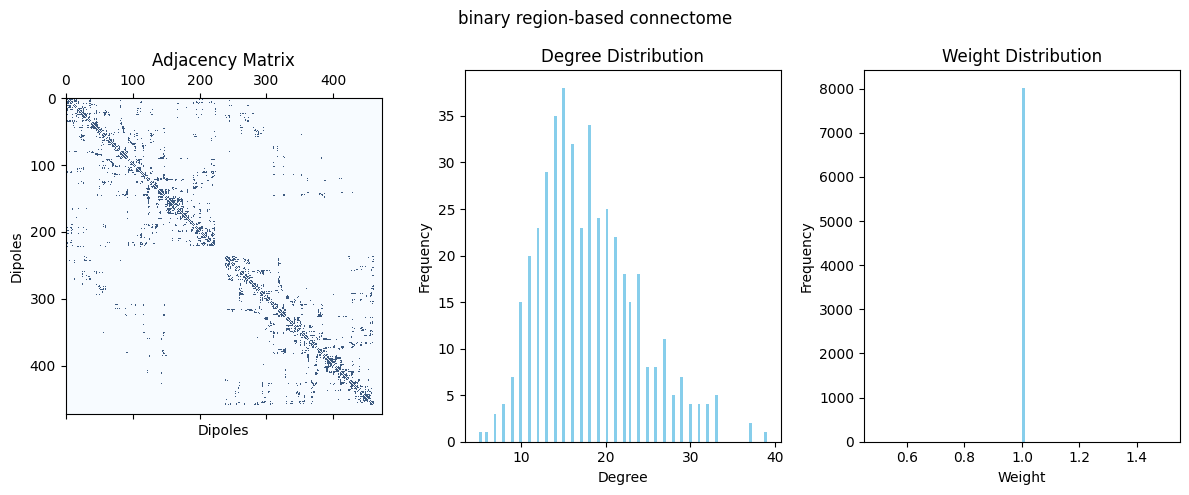

In [11]:
# ------------ Parameters -------------
weights = "binary"
# -------------------------------------

if weights == "density":
    conn = conn_rb_density
elif weights == "length":
    conn = conn_rb_length
else:
    conn = conn_rb_length > 0

mm.head.print_connectome_summary(conn)
mm.viz.plot_connectome(conn, name=f"{weights} region-based connectome", nonzero=True)

💾 **Save region-based connectome**

In [12]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving region-based SC for subject: {sub}")
np.save(folder/f"{sub}_atlas-MultiConn2022_res-scale4_desc-numfibers_conn.npy", conn_rb_density)
np.save(folder/f"{sub}_atlas-MultiConn2022_res-scale4_desc-fiberlength_conn.npy", conn_rb_length)

Saving region-based SC for subject: vepcon_sub-10


#### Dipole-based connectome

The dipole-based connectome is the one used for source imaging.

📥 **<font color=pink>Inputs</font>**
<br>**data**:
- `pruned_tracto`: Tractogram – contains streamlines (tracts).
- `src`: Source space – defines dipole positions in freesurfer space.

<br>**transforms**:
- `t12diff`: Affine transformation – (diffusion space -> T1-ras space)
- `tkras2ras`: Affine transformation – (freesurfer -> T1-ras space)


📥 **<font color=pink>Outputs</font>**
- `conn_density`: Dipole-based connectome with number of fibers as weights.
- `conn_length`: Dipole-based connectome with fiber lengths as weights.

In [13]:
conn_density = mm.head.connectome_from_tracts(pruned_tracto, data["src"], data["t12diff"], data["tkras2ras"])
conn_length  = mm.head.connectome_from_tracts(pruned_tracto, data["src"], data["t12diff"], data["tkras2ras"], lengths=True)

📊 **Summary of dipole-based connectomes** <br>

🎚️ **<font color=pink>Connectome information</font>**:
- `weights`: choose amongst ["density", "length", "binary"]

Number of nodes: 7465
Total number of connections: 36204.0 (sparsity = 0.0013%)
Minimum (non-zero) weight: 4.999960422515869
Maximum weight: 147.99996948242188
Number of isolated nodes: 259 (ratio = 3.47)%


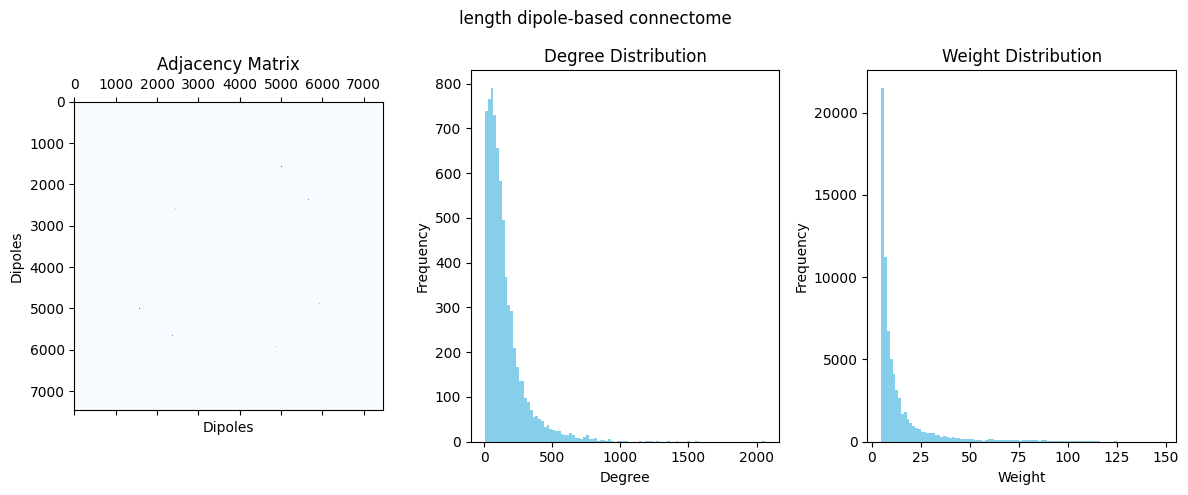

In [14]:
# ------------ Parameters -------------
weights = "length"
# -------------------------------------

if weights == "density":
    conn = conn_density
elif weights == "length":
    conn = conn_length
else:
    conn = conn_length > 0

mm.head.print_connectome_summary(conn)
mm.viz.plot_connectome(conn, name=f"{weights} dipole-based connectome", nonzero=True)

The connectivity matrix appears sparse, primarily because it contains a large number of nodes. As a result, individual entries in the adjacency matrix are too small to be visible without zooming in. <br>

A more concerning issue is that some dipoles show no connections. This may be due to streamline endpoints being localized primarily within the gyri (as shown in the first 3D plot), which reduces the likelihood of forming connections with dipoles located in the sulci. <br>

Additionally, we currently assume that each streamline has a single, well-defined endpoint. However, this assumption oversimplifies reality—streamlines are composed of multiple nerve fibers that may terminate in different locations. This limitation becomes significant when analyzing high-resolution connectomes and should not be overlooked. <br>

In the following section, we implement the solutions proposed by Sina Mansour et al. (2020) to address these challenges in high-resolution connectome construction.

📊 **Visualize isolated nodes** <br>

In [15]:
# Visualize isolated nodes
isolated_nodes = np.argwhere(np.sum(conn_length>0, axis=1)==0).squeeze()
targets = np.zeros(mm.head.get_ndipole(data["src"]))
targets[isolated_nodes] = 1

mm.viz.plot_brain(data["src"], targets, overlay=data["ctx"], tkras2ras=data["tkras2ras"]).show()

Widget(value='<iframe src="http://localhost:39837/index.html?ui=P_0x7103aef2a690_2&reconnect=auto" class="pyvi…

In [16]:
mm.viz.plot_graph(mm.head.get_dipole_positions(data["src"]), (conn_length>0) * (conn_length<5)).show()

Widget(value='<iframe src="http://localhost:39837/index.html?ui=P_0x7103d0176990_3&reconnect=auto" class="pyvi…

## 3. ⚙️ Smooth connectomes

The endpoints of streamlines are usually connected to multiple neurons. If the spacing between dipoles is very small, than the streamlines are most likely originating/terminating in multiple dipoles. To incorporate this in our connectomes, we can smooth the endpoints of streamlines with a gaussian kernel of approximately 2 mm (methodology described in [Sina Mansour et. al (2020)](https://www.sciencedirect.com/science/article/pii/S1053811920311800?via%3Dihub#sec0035)). Distances are to be understood as geodesic distances on the brain surface. <br>
🚨 Only recommended if dipole spacing is smaller than 2 mm 🚨<br>

#### Smooth weight connectivity according to Sina Mansour et. al (2020)
NOT IMPLEMENTED

## 4. ⚙️ Build connectomes from geometry
Tractography reveals the pathways within the white matter, but it is also understood that neurons communicate with their neighbors through the gray matter. To simulate this interaction, we artificially introduce connections between neighboring dipoles. Distance to measure closest neighbors is the geodesic distance on the surface.

📥 **<font color=pink>Inputs</font>**

- `src`: Source space – Contains geodesic distances between dipoles

📥 **<font color=pink>Outputs</font>**

- `conn_geom_length`: Connectome from geometry with geodesic distance as weights.

🎚️ **<font color=pink>Geometry</font>**:
- `maximum_dist`: Maximum distance in [mm] at which to connect a neighbor.
- `maximum_neigh`: Maximum number of neighbors to select.

In [23]:
# ------------ Parameters -------------
maximum_dist  = 5
maximum_neigh = 3
# -------------------------------------

conn_geom = mm.head.connectome_from_geometry(data["src"], weights=True)

📊 **Summary of dipole-based connectomes** <br>

🎚️ **<font color=pink>Connectome information</font>**:
- `weights`: choose amongst ["length", "binary"]

Number of nodes: 7465
Total number of connections: 57045.0 (sparsity = 0.00205%)
Minimum (non-zero) weight: True
Maximum weight: True
Number of isolated nodes: 0 (ratio = 0.0)%


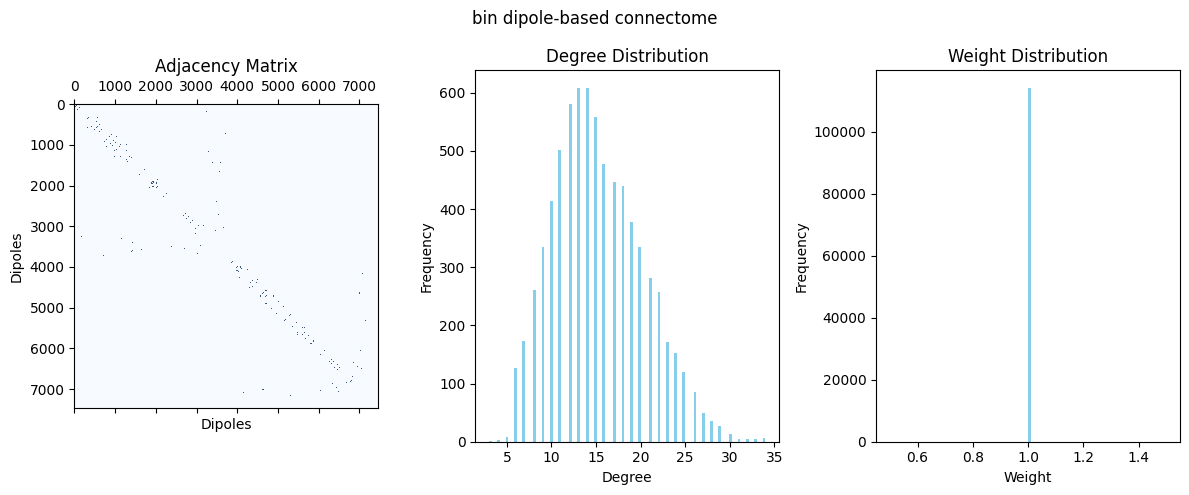

In [24]:
# ------------ Parameters -------------
weights = "bin"
# -------------------------------------

if weights == "length":
    conn = conn_geom
else:
    conn = conn_geom > 0

mm.head.print_connectome_summary(conn)
mm.viz.plot_connectome(conn, name=f"{weights} dipole-based connectome", nonzero=True)

In [25]:
mm.viz.plot_graph(mm.head.get_dipole_positions(data["src"]), conn>0).show()

Widget(value='<iframe src="http://localhost:39837/index.html?ui=P_0x7103ae6604d0_6&reconnect=auto" class="pyvi…

## 5. ⚙️ Combine tractography and geometry
Both tractography and geometry can be represented with weights corresponding to distances — tract distances for tractography and geodesic distances for geometry. In principle, we could combine the tractography and geometry graphs into a single distance-based graph. However, unlike tractography, we cannot estimate the number of fibers in the geometric model, so we must disregard fiber counts from this point forward.

📥 **<font color=pink>Inputs</font>**

- `conn_length`: Connectome from tractography with fiber length as weights.
- `conn_geom`: Connectome from geometry with geodesic distance as weigths.

📥 **<font color=pink>Outputs</font>**

- `final_conn`: Distance based connectome with tractography and geometry information.

🎚️ **<font color=pink>Geometry</font>**:
- `maximum_dist`: Maximum distance in [mm] at which to connect a neighbor.
- `maximum_neigh`: Maximum number of neighbors to select.

In [26]:
final_conn = conn_length.copy()

# add geometry on length connectome
geom_idx = np.argwhere(conn_geom > 0)
final_conn[geom_idx[:,0], geom_idx[:,1]] = conn_geom[geom_idx[:,0], geom_idx[:,1]]

💾 **Save the SC**

In [ ]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography and geometry for subject: {sub}")
np.save(folder/f"{sub}_atlas-sourcespace_desc-distance_conn.npy", final_conn)

Saving SC from tractography and geometry for subject: vepcon_sub-10


## 6. Connectome Spectrum Transform

The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eignevectors) of this transform are characteristic of the connectome.

📥 **<font color=pink>Inputs</font>**

- `whole_sc`: Final connectome

📥 **<font color=pink>Outputs</font>**

- `cst`: Connectome spectrum transform
- `eig`: Eigenvalues

In [19]:
coords = mm.utils.get_src_position(data["src"])

G = pygsp.graphs.Graph(geom_sc_lengths, lap_type="normalized", coords=coords)
G.compute_fourier_basis()

cst_lengths = G.U.T
eig_lengths = G.e

G = pygsp.graphs.Graph(geom_sc_weights, lap_type="normalized", coords=coords)
G.compute_fourier_basis()

cst_weights = G.U.T
eig_lengths = G.e

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/pygsp/graphs/graph.py:496: RuntimeWarning: divide by zero encountered in power
  d = np.power(self.dw, -0.5)
2025-10-17 11:32:36,673:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.
2025-10-17 11:32:44,149:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (4961 x 4961) may take some time.


🌟 **Visualize harmonics**

In [20]:
############## Parameters #############
cst = cst_lengths
#######################################

mm.viz.plot_harmonics(data["src"], cst).show()

Widget(value='<iframe src="http://localhost:42947/index.html?ui=P_0x73545c182c90_1&reconnect=auto" class="pyvi…

#### 💾 Save the SC

In [21]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from tractography for subject: {sub}")
np.save(folder/f"{sub}_sc-length-tracto.npy", geom_sc_lengths)
np.save(folder/f"{sub}_sc-weight-tracto.npy", geom_sc_weights)

Saving SC from tractography for subject: vepcon_sub-10


#### 💾 Save the CST

In [22]:
mm_dir = reader.config["MM_DIR"]
sub    = data["sub"]

folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from tractography for subject: {sub}")
np.save(folder/f"{sub}_cst.npy", cst_lengths)

print(f"Saving eigenvalues for subject: {sub}")
np.save(folder/f"{sub}_eig.npy", eig_lengths)

Saving CST from tractography for subject: vepcon_sub-10
Saving eigenvalues for subject: vepcon_sub-10


In [ ]:
np.load(allo)